# 06_1 · Графіки помилок

Продовження `06`. Модель — LightGBM (20 ознак) + динамічна поправка, перевірка 23 гру 2025 – 24 жов 2026.

1. прогноз і реальність по днях;
2. помилка у % по місяцях і сезонах;
3. чи росте помилка, що далі від даних, на яких модель вчилась.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates, lightgbm as lgb
import data_io as io, evaluate as ev
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.max_columns', 60)
df, train, test = ev.load()
clean = df[df.enough & ~df.clipped]; y = clean.pv_w
MONTHS = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']
SEASON = {12: 'зима', 1: 'зима', 2: 'зима', 3: 'весна', 4: 'весна', 5: 'весна', 6: 'літо', 7: 'літо', 8: 'літо', 9: 'осінь', 10: 'осінь', 11: 'осінь'}
S = pd.Timestamp(ev.SPLIT, tz='UTC'); t = test.index
saved = pd.read_pickle(io.DATA / 'corrections.pkl')
base = saved['lgb']['без поправки'].reindex(clean.index)
pred = (base * ev.weighted_factor(base, y, 2)).reindex(t)
raw = base.reindex(t)

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{MONTHS[mdates.num2date(x).month - 1]}\n{mdates.num2date(x).year}" if mdates.num2date(x).month in (1, 12) else MONTHS[mdates.num2date(x).month - 1]))
    ax.set_xlabel('')

## 1. Прогноз і реальність по днях

Енергія за день, кВт·год (лише чисті години — без обрізаного сонця, тож це не вся генерація дня). Тонкі лінії — дні, товсті — середнє за 7 днів.

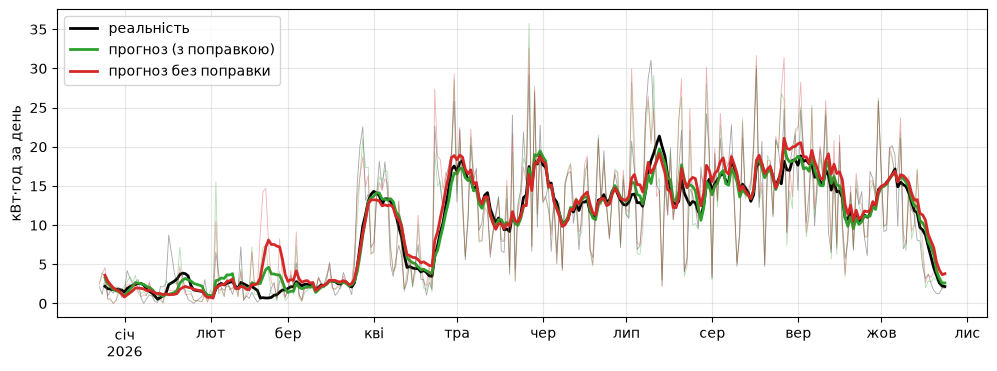

In [2]:
day = t.tz_convert(io.TZ).normalize()
Dd = pd.DataFrame({'реальність': test.pv_w.groupby(day).sum(), 'прогноз (з поправкою)': pred.groupby(day).sum(),
                   'прогноз без поправки': raw.groupby(day).sum()}) / 1000
fig, ax = plt.subplots()
for c, color in (('реальність', 'k'), ('прогноз (з поправкою)', 'tab:green'), ('прогноз без поправки', 'tab:red')):
    ax.plot(Dd.index, Dd[c], color=color, lw=.6, alpha=.35)
    ax.plot(Dd.index, Dd[c].rolling(7, min_periods=3).mean(), color=color, lw=2, label=c)
ax.set_ylabel('кВт·год за день'); ax.legend(loc='upper left'); month_axis(ax); plt.show()

Промах за день (прогноз − реальність): вище нуля — модель завищила, нижче — занизила.

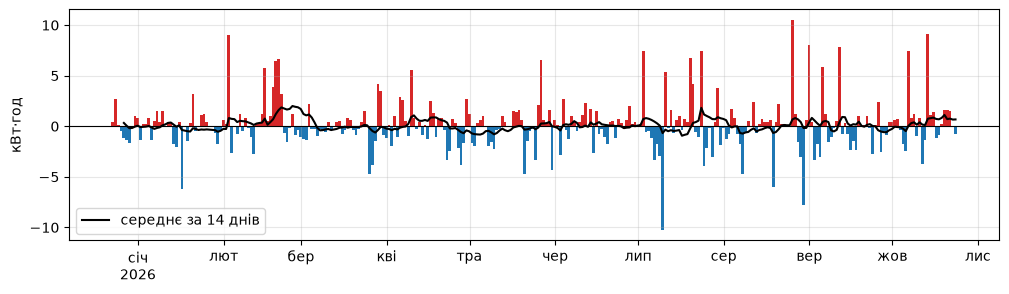

In [3]:
fig, ax = plt.subplots(figsize=(12, 3))
diff = Dd['прогноз (з поправкою)'] - Dd['реальність']
ax.bar(Dd.index, diff, color=np.where(diff > 0, 'tab:red', 'tab:blue'), width=1)
ax.plot(Dd.index, diff.rolling(14, min_periods=5).mean(), c='k', lw=1.5, label='середнє за 14 днів')
ax.axhline(0, c='k', lw=.8); ax.set_ylabel('кВт·год'); ax.legend(); month_axis(ax); plt.show()

## 2. Помилка у % по місяцях і сезонах

**Промах, %** — середній промах за годину від середньої генерації (nMAE). **Зсув, %** — систематичне завищення (+) чи заниження (−). Взимку сонця мало — і відсотки від малого більші.

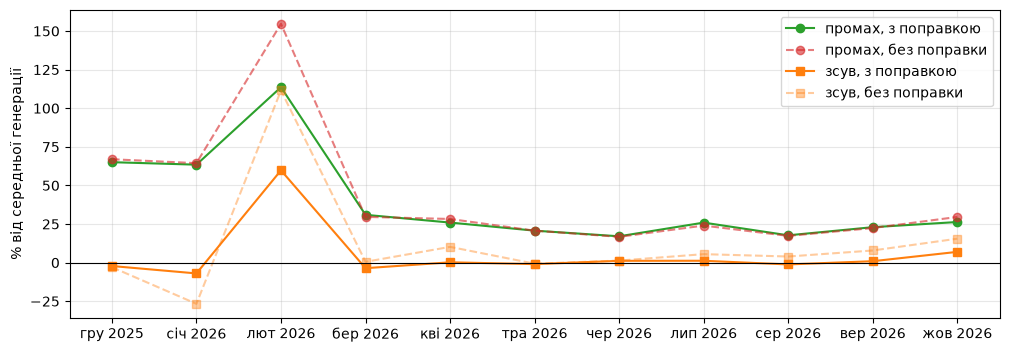

k,гру 2025,січ 2026,лют 2026,бер 2026,кві 2026,тра 2026,чер 2026,лип 2026,сер 2026,вер 2026,жов 2026
"промах, %",65,63,114,31,26,21,17,26,18,23,26
"зсув, %",-2,-7,60,-4,0,-1,1,1,-1,1,7


In [4]:
loc = t.tz_convert(io.TZ)
key = [f'{MONTHS[m - 1]} {yy}' for yy, m in zip(loc.year, loc.month)]
def pct(p):
    g = pd.DataFrame({'y': test.pv_w.to_numpy(), 'p': p.to_numpy(), 'k': key}, index=t).groupby('k', sort=False)
    return pd.DataFrame({'промах, %': g.apply(lambda x: (x.p - x.y).abs().mean() / x.y.mean() * 100),
                         'зсув, %': g.apply(lambda x: (x.p - x.y).mean() / x.y.mean() * 100)})
Mw, Mr = pct(pred), pct(raw)
fig, ax = plt.subplots()
ax.plot(Mw.index, Mw['промах, %'], 'o-', c='tab:green', label='промах, з поправкою')
ax.plot(Mr.index, Mr['промах, %'], 'o--', c='tab:red', alpha=.6, label='промах, без поправки')
ax.plot(Mw.index, Mw['зсув, %'], 's-', c='tab:orange', label='зсув, з поправкою')
ax.plot(Mr.index, Mr['зсув, %'], 's--', c='tab:orange', alpha=.4, label='зсув, без поправки')
ax.axhline(0, c='k', lw=.8); ax.set_ylabel('% від середньої генерації'); ax.legend(); plt.show()
Mw.round().astype(int).T

In [5]:
sea = pd.Series([SEASON[m] for m in loc.month], index=t)
rows = {}
for s in ['зима', 'весна', 'літо', 'осінь']:
    m = (sea == s).to_numpy()
    rows[s] = {'годин': int(m.sum()), 'середня генерація, Вт': int(test.pv_w[m].mean()),
               'промах, Вт': ev.metrics(test.pv_w[m], pred[m])['MAE, Вт'],
               'промах, %': round(ev.metrics(test.pv_w[m], pred[m])['nMAE, %']),
               'зсув, %': round((pred[m] - test.pv_w[m]).mean() / test.pv_w[m].mean() * 100),
               'промах без поправки, %': round(ev.metrics(test.pv_w[m], raw[m])['nMAE, %'])}
pd.DataFrame(rows).rename_axis('сезон (перевірка)', axis=1)

сезон (перевірка),зима,весна,літо,осінь
годин,436,693,850,494
"середня генерація, Вт",284,1263,1591,1293
"промах, Вт",240,307,324,311
"промах, %",84,24,20,24
"зсув, %",21,-1,0,3
"промах без поправки, %",102,25,20,25


## 3. Чи росте помилка, що далі від навчання

Порівнюємо три моделі на тому самому другому році:
- **навчена раз на першому році** і більше не перенавчалась — що далі від 2025-го, то більше могла б «застаріти»;
- те саме **+ динамічна поправка**;
- **щомісяця перенавчання + динамічна поправка** (наша).

Якщо помилка першої росте з місяцями, а наша — ні, значить модель старіє, і перенавчання з поправкою це лікують.

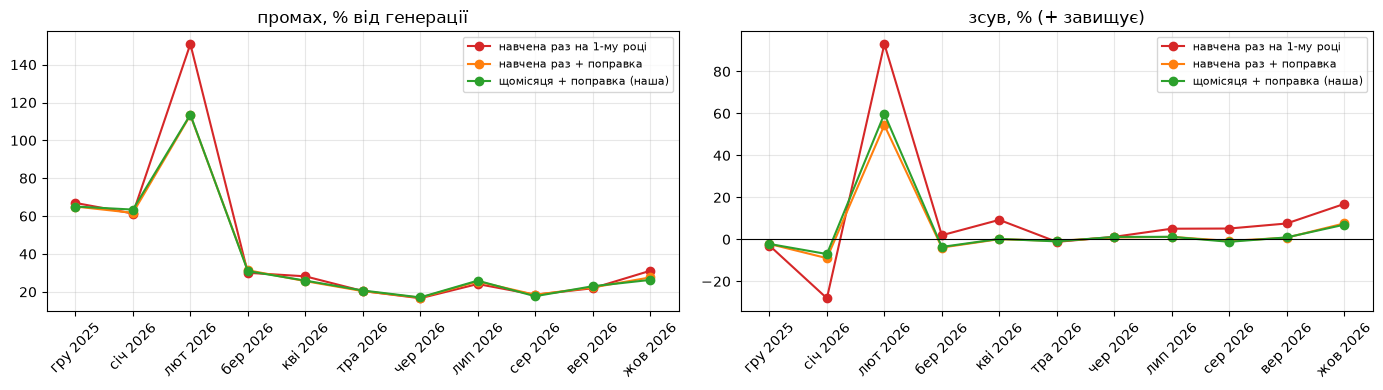

k,гру 2025,січ 2026,лют 2026,бер 2026,кві 2026,тра 2026,чер 2026,лип 2026,сер 2026,вер 2026,жов 2026
навчена раз на 1-му році,67,61,151,30,28,20,17,24,18,22,31
навчена раз + поправка,65,62,113,31,26,20,17,25,18,22,28
щомісяця + поправка (наша),65,63,114,31,26,21,17,26,18,23,26


In [6]:
PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=0, verbose=-1)
feats = ev.variants()['повний (20 ознак)']
y1 = clean[clean.index < S]
static_all = pd.Series(np.clip(lgb.LGBMRegressor(**PARAMS).fit(y1[feats], y1.pv_w).predict(clean[feats]), 0, None), index=clean.index)
static = static_all.reindex(t)
static_cor = (static_all * ev.weighted_factor(static_all, y, 2)).reindex(t)
V = {'навчена раз на 1-му році': static, 'навчена раз + поправка': static_cor, 'щомісяця + поправка (наша)': pred}
P = {k: pct(v) for k, v in V.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (k, v), c in zip(P.items(), ['tab:red', 'tab:orange', 'tab:green']):
    axes[0].plot(v.index, v['промах, %'], 'o-', c=c, label=k)
    axes[1].plot(v.index, v['зсув, %'], 'o-', c=c, label=k)
axes[0].set_title('промах, % від генерації'); axes[1].set_title('зсув, % (+ завищує)')
axes[1].axhline(0, c='k', lw=.8)
for a in axes: a.tick_params(axis='x', rotation=45); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame({k: v['промах, %'].round().astype(int) for k, v in P.items()}).T

In [7]:
rows = {k: {**ev.metrics(test.pv_w, v), 'краще за «навчена раз», % вибірок': '—' if k.startswith('навчена раз на') else round(ev.daily_bootstrap(t, test.pv_w, v, static) * 100)}
        for k, v in V.items()}
R = pd.DataFrame(rows).T
for c in ('MAE, Вт', 'RMSE, Вт', 'зсув, Вт'): R[c] = R[c].astype(int)
R.rename_axis('модель')

,"MAE, Вт","nMAE, %","RMSE, Вт","зсув, Вт","краще за «навчена раз», % вибірок"
модель,,,,,
навчена раз на 1-му році,311,25.7,523,73,—
навчена раз + поправка,302,24.9,500,15,92.0
щомісяця + поправка (наша),302,25.0,502,16,90.0


## Висновки

1. **Помилка — це сезон.** Зима: промах 84 % від генерації (лют — 111 %), весна 24 %, літо 20 %, осінь 24 %. У ватах зима навпаки найменша (238 Вт проти 322 улітку): сонця мало, тож кожна помилка — великий відсоток.
2. **Помилка з часом не росте.** Модель, навчена раз на 2025-му і більше не перенавчалась, улітку й восени 2026-го помиляється так само, як щомісячна (тра–вер 16–24 %). Вона не «старіє».
3. **Різниця лише там, де змінився стан панелей:** лют (сніг, ожеледиця) і жов. Без поправки «навчена раз» у лютому — 136 %, з поправкою — 107 %.
4. **Щомісячне перенавчання нічого не додає:** «навчена раз + поправка» — 299 Вт, «щомісяця + поправка» — 300. На Pi можна перенавчати рідко.
5. **Зсув з поправкою ~0** в усі місяці, крім лютого (+54 %: сніг після ожеледиці 26 січ) і жовтня (+7 %).